In [ ]:
# Data preparation
'''Turns the raw FloodCastBench files into lined-up arrays and saves them to Google Drive,
so the next notebooks can load them in seconds.

Saved for each dataset:
- water depth, one map every 30 minutes
- rain on the same grid
- ground height, land cover and permanent water (rivers and lakes)
- map coordinates, for plotting predictions on real maps'''

'Turns the raw FloodCastBench files into lined-up arrays and saves them to Google Drive,\nso the next notebooks can load them in seconds.\n\nSaved for each dataset:\n- water depth, one map every 30 minutes\n- rain on the same grid\n- ground height, land cover and permanent water (rivers and lakes)\n- map coordinates, for plotting predictions on real maps'

In [ ]:
# Install rasterio, the library that reads map files (.tif)
!pip install -q rasterio


In [ ]:
import os
import glob
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
from huggingface_hub import snapshot_download, HfApi
from google.colab import drive

In [ ]:
# Name of the dataset on Hugging Face
REPO_ID = "mahajananhad/floodcastbench"

# Where the raw files are downloaded on Colab (this folder is wiped when the session ends)
RAW_DIR = "/content/floodcastbench"

# Where the prepared data is saved on Google Drive (this folder is kept)
SAVE_DIR = "/content/drive/MyDrive/Flood_project/prepared_data"

# Time between two prepared maps: 1800 seconds = 30 minutes, the same spacing as the rain maps
STEP_SECONDS = 1800

## Where each depth map sits
Rain, ground height and land cover are all stored on one 30 m grid.
Each depth map sits somewhere inside that grid:
- `scale` = how many 30 m cells fit along one side of a depth cell
- `row_offset`, `col_offset` = where the depth map's top-left corner is on the 30 m grid

These positions are tested against the data in the alignment check further down.

In [ ]:
DATASETS = {
    "Australia_30m": {
        "region": "Australia",
        "folder": "High-fidelity flood forecasting/30m/Australia",
        "resolution_m": 30,
        "scale": 1,
        "row_offset": 0,
        "col_offset": 0,
    },
    "UK_30m": {
        "region": "UK",
        "folder": "High-fidelity flood forecasting/30m/UK",
        "resolution_m": 30,
        "scale": 1,
        "row_offset": 5,
        "col_offset": 5,
    },
    "Australia_60m": {
        "region": "Australia",
        "folder": "High-fidelity flood forecasting/60m/Australia",
        "resolution_m": 60,
        "scale": 2,
        "row_offset": 0,
        "col_offset": 0,
    },
    "UK_60m": {
        "region": "UK",
        "folder": "High-fidelity flood forecasting/60m/UK",
        "resolution_m": 60,
        "scale": 2,
        "row_offset": 5,
        "col_offset": 5,
    },
    "Pakistan_480m": {
        "region": "Pakistan",
        "folder": "Low-fidelity flood forecasting/480m/Pakistan",
        "resolution_m": 480,
        "scale": 16,
        "row_offset": 42,
        "col_offset": 178,
    },
    "Mozambique_480m": {
        "region": "Mozambique",
        "folder": "Low-fidelity flood forecasting/480m/Mozambique",
        "resolution_m": 480,
        "scale": 16,
        "row_offset": 150,
        "col_offset": 50,
    },
}

# Map projection code of each region (UTM zones listed in the dataset's Spatial_References.txt)
EPSG_CODES = {
    "Australia": 32756,
    "UK": 32630,
    "Pakistan": 32642,
    "Mozambique": 32736,
}

# Name and colour of each land-cover code
LAND_COVER = {
    1:  ("Water",              "#1f78b4"),
    2:  ("Trees",              "#33a02c"),
    4:  ("Flooded vegetation", "#a6cee3"),
    5:  ("Crops",              "#fdbf6f"),
    7:  ("Buildings",          "#e31a1c"),
    8:  ("Bare ground",        "#b15928"),
    9:  ("Snow / ice",         "#ffffff"),
    10: ("Clouds",             "#bdbdbd"),
    11: ("Rangeland",          "#b2df8a"),
}

In [ ]:
# Connect Google Drive and create the folder for the prepared data
drive.mount("/content/drive")

os.makedirs(SAVE_DIR, exist_ok=True)
print("Prepared data will be saved in:", SAVE_DIR)

Mounted at /content/drive
Prepared data will be saved in: /content/drive/MyDrive/Flood_project/prepared_data


In [ ]:
# Load the Hugging Face token from Colab's secrets (key icon on the left)
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("Token found")

except Exception:
    HF_TOKEN = None
    print("No token found, downloading without one")

Token found


## Download only the files we need
One depth map every 30 minutes (the rain's spacing), plus all rain, ground height,
land-cover and map-coordinate files.

In [ ]:
api = HfApi()
all_files = api.list_repo_files(REPO_ID, repo_type="dataset", token=HF_TOKEN)

files_needed = []

for file_name in all_files:

    # Rain, ground height, land cover and map-coordinate files
    if file_name.startswith("Relevant data/Rainfall/"):
        files_needed.append(file_name)

    elif file_name.startswith("Relevant data/DEM/"):
        files_needed.append(file_name)

    elif file_name.startswith("Relevant data/Land use and land cover/"):
        files_needed.append(file_name)

    elif file_name.startswith("Relevant data/Georeferenced files/"):
        files_needed.append(file_name)

    # Depth maps: keep only the ones that fall exactly on a 30-minute mark
    elif file_name.startswith("High-fidelity") or file_name.startswith("Low-fidelity"):
        seconds = int(os.path.basename(file_name).replace(".tif", ""))

        if seconds % STEP_SECONDS == 0:
            files_needed.append(file_name)

print("Files in the dataset:", len(all_files))
print("Files we need:       ", len(files_needed))

Files in the dataset: 14870
Files we need:        3822


In [ ]:
start_time = time.time()

# Try up to 5 times, because large downloads sometimes get interrupted.
# This cell can sit quietly for a minute or two before the progress bar appears.
for attempt in range(1, 6):

    try:
        snapshot_download(
            repo_id=REPO_ID,
            repo_type="dataset",
            local_dir=RAW_DIR,
            token=HF_TOKEN,
            allow_patterns=files_needed,
            max_workers=8,
        )
        print("Download complete")
        break

    except Exception as error:
        print("Attempt", attempt, "failed:", error)
        print("Waiting 60 seconds before trying again")
        time.sleep(60)

print("Time taken:", round((time.time() - start_time) / 60, 1), "minutes")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3822 files:   0%|          | 0/3822 [00:00<?, ?it/s]

Download complete
Time taken: 6.3 minutes


In [ ]:
# Check that every needed file arrived
missing_files = []

for file_name in files_needed:
    if not os.path.exists(os.path.join(RAW_DIR, file_name)):
        missing_files.append(file_name)

print("Files missing:", len(missing_files))

if len(missing_files) > 0:
    print("Examples:", missing_files[:5])
    print("Run the download cell again")

Files missing: 0


In [ ]:
def get_seconds(file_path):
    """Turns a depth file name like '1800.tif' into the number 1800."""

    file_name = os.path.basename(file_path)

    return int(file_name.replace(".tif", ""))


def get_depth_files(dataset):
    """Returns the 30-minute depth maps of one dataset in time order."""

    folder = os.path.join(RAW_DIR, DATASETS[dataset]["folder"])
    files = glob.glob(os.path.join(folder, "*.tif"))

    # Keep only maps on a 30-minute mark
    files = [f for f in files if get_seconds(f) % STEP_SECONDS == 0]

    files.sort(key=get_seconds)

    return files


def get_rain_files(region):
    """Returns the rain maps of one region in time order (names are date and time, so alphabetical order works)."""

    folder = os.path.join(RAW_DIR, "Relevant data", "Rainfall", region + " flood")
    files = glob.glob(os.path.join(folder, "*.tif"))
    files.sort()

    return files


def read_on_depth_grid(file_path, dataset, rows, columns, method):
    """Reads the part of a 30 m map that lies under the depth map,
    and shrinks it onto the depth map's grid using the given method."""

    info = DATASETS[dataset]
    scale = info["scale"]

    # The area of the 30 m map that the depth map covers
    window = Window(
        col_off=info["col_offset"],
        row_off=info["row_offset"],
        width=columns * scale,
        height=rows * scale,
    )

    with rasterio.open(file_path) as source:
        data = source.read(1, window=window, out_shape=(rows, columns), resampling=method)

    data = data.astype("float32")

    # These files use a huge negative number to mean "no data". None should be under the depth map.
    if np.any(data < -1e30):
        raise ValueError("No-data values found under the depth map in " + file_path)

    return data


def land_cover_positions(land_cover):
    """Turns land-cover codes (1, 2, 4, ...) into positions (0, 1, 2, ...) so each gets its own colour."""

    positions = np.full(land_cover.shape, np.nan)

    for position, code in enumerate(LAND_COVER.keys()):
        positions[land_cover == code] = position

    return positions


# Colour scales used in the plots
land_cover_colours = ListedColormap([colour for name, colour in LAND_COVER.values()])
land_cover_names = [name for name, colour in LAND_COVER.values()]

# Blue colour scale that starts at light blue instead of white, so shallow water stays visible
water_colours = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))

## Check that every layer is big enough to cover the depth map

In [ ]:
DEPTH_SHAPES = {}
size_rows = []

for dataset, info in DATASETS.items():
    region = info["region"]

    # Size of the depth map
    with rasterio.open(get_depth_files(dataset)[0]) as source:
        rows = source.height
        columns = source.width

    DEPTH_SHAPES[dataset] = (rows, columns)

    # Area of the 30 m grid that the depth map needs
    needed_rows = info["row_offset"] + rows * info["scale"]
    needed_columns = info["col_offset"] + columns * info["scale"]

    layers = {
        "Ground height": os.path.join(RAW_DIR, "Relevant data", "DEM", region + "_DEM.tif"),
        "Land cover": os.path.join(RAW_DIR, "Relevant data", "Land use and land cover", region + ".tif"),
        "Rain": get_rain_files(region)[0],
    }

    for layer_name, path in layers.items():
        with rasterio.open(path) as source:
            fits = needed_rows <= source.height and needed_columns <= source.width
            layer_size = str(source.height) + " x " + str(source.width)

        size_rows.append({
            "Dataset": dataset,
            "Layer": layer_name,
            "Layer size": layer_size,
            "Area needed": str(needed_rows) + " x " + str(needed_columns),
            "Big enough?": fits,
        })

display(pd.DataFrame(size_rows))

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


,Dataset,Layer,Layer size,Area needed,Big enough?
0,Australia_30m,Ground height,1073 x 1073,1073 x 1073,True
1,Australia_30m,Land cover,1073 x 1073,1073 x 1073,True
2,Australia_30m,Rain,1073 x 1073,1073 x 1073,True
3,UK_30m,Ground height,180 x 285,175 x 280,True
4,UK_30m,Land cover,180 x 285,175 x 280,True
5,UK_30m,Rain,180 x 285,175 x 280,True
6,Australia_60m,Ground height,1073 x 1073,1072 x 1072,True
7,Australia_60m,Land cover,1073 x 1073,1072 x 1072,True
8,Australia_60m,Rain,1073 x 1073,1072 x 1072,True
9,UK_60m,Ground height,180 x 285,175 x 279,True


## Save the depth maps

In [ ]:
# Average depth of each cell over the whole flood, kept for the alignment check below
depth_averages = {}

for dataset in DATASETS:
    files = get_depth_files(dataset)
    rows, columns = DEPTH_SHAPES[dataset]

    # Check that no 30-minute map is missing
    seconds = [get_seconds(f) for f in files]
    expected = list(range(0, seconds[-1] + 1, STEP_SECONDS))

    if seconds != expected:
        print(dataset, "- WARNING: some 30-minute maps are missing")

    # Empty array to fill: one map per 30 minutes
    depth = np.zeros((len(files), rows, columns), dtype="float32")

    for step, file_path in enumerate(files):
        with rasterio.open(file_path) as source:
            depth[step] = source.read(1)

    # Save to this dataset's folder on Drive
    dataset_dir = os.path.join(SAVE_DIR, dataset)
    os.makedirs(dataset_dir, exist_ok=True)
    np.save(os.path.join(dataset_dir, "depth.npy"), depth)

    depth_averages[dataset] = depth.mean(axis=0)

    print(dataset, "- saved", len(files), "maps of", rows, "x", columns)

    # Free the memory before the next dataset
    del depth

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Australia_30m - saved 481 maps of 1073 x 1073
UK_30m - saved 145 maps of 170 x 275
Australia_60m - saved 481 maps of 536 x 536
UK_60m - saved 145 maps of 85 x 137
Pakistan_480m - saved 673 maps of 810 x 441
Mozambique_480m - saved 289 maps of 151 x 138


## Alignment check
Rivers and lakes on the land-cover map should sit exactly where the flood maps have deep water.
The land-cover map is shifted a little in every direction to find where the two match best.

In [ ]:
def alignment_scores(dataset):
    """Shifts the land-cover map around the position in use and measures, for every shift,
    how well its rivers and lakes match the deep water. Returns the scores and the shifts tried."""

    info = DATASETS[dataset]
    scale = info["scale"]
    rows, columns = DEPTH_SHAPES[dataset]

    # Read the full land-cover map and mark rivers and lakes
    land_cover_path = os.path.join(RAW_DIR, "Relevant data", "Land use and land cover", info["region"] + ".tif")

    with rasterio.open(land_cover_path) as source:
        land_cover = source.read(1)

    water = (land_cover == 1).astype("uint8")

    # Try shifts of up to 3 depth cells in every direction
    largest_shift = 3 * scale
    shift_step = max(1, scale // 4)
    shifts = list(range(-largest_shift, largest_shift + 1, shift_step))

    scores = np.full((len(shifts), len(shifts)), np.nan)

    for i, row_shift in enumerate(shifts):
        for j, column_shift in enumerate(shifts):

            top = info["row_offset"] + row_shift
            left = info["col_offset"] + column_shift
            bottom = top + rows * scale
            right = left + columns * scale

            # Skip shifts that would go past the edge of the land-cover map
            if top < 0 or left < 0 or bottom > water.shape[0] or right > water.shape[1]:
                continue

            # Share of each depth cell that is river or lake
            piece = water[top:bottom, left:right]
            water_share = piece.reshape(rows, scale, columns, scale).mean(axis=(1, 3))

            # How closely "river or lake" follows "deep water" (1 = perfectly)
            scores[i, j] = np.corrcoef(water_share.ravel(), depth_averages[dataset].ravel())[0, 1]

    return scores, shifts

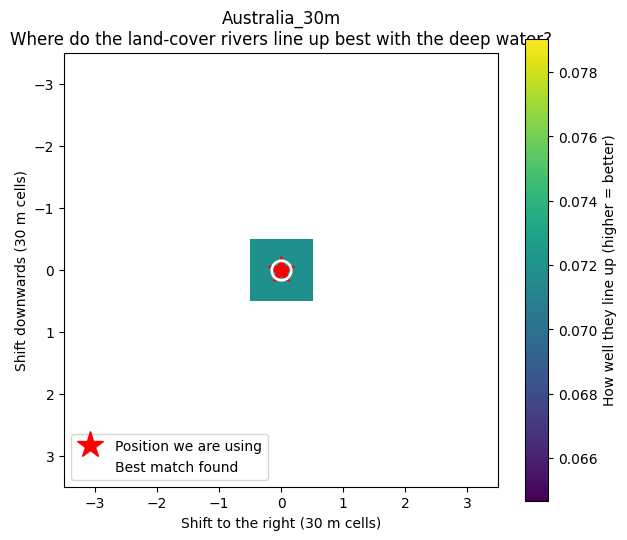

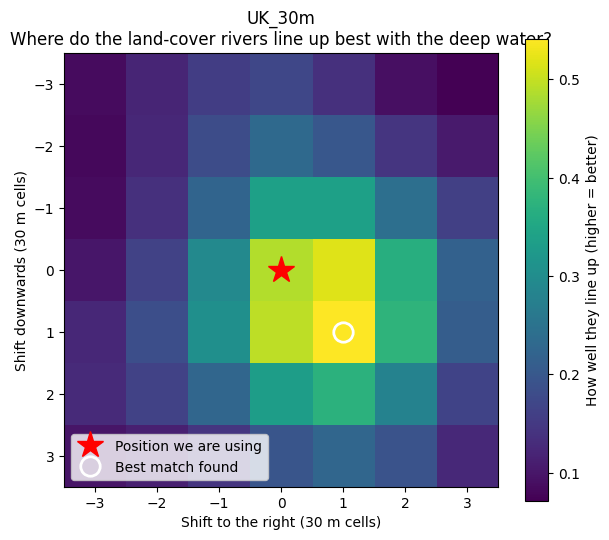

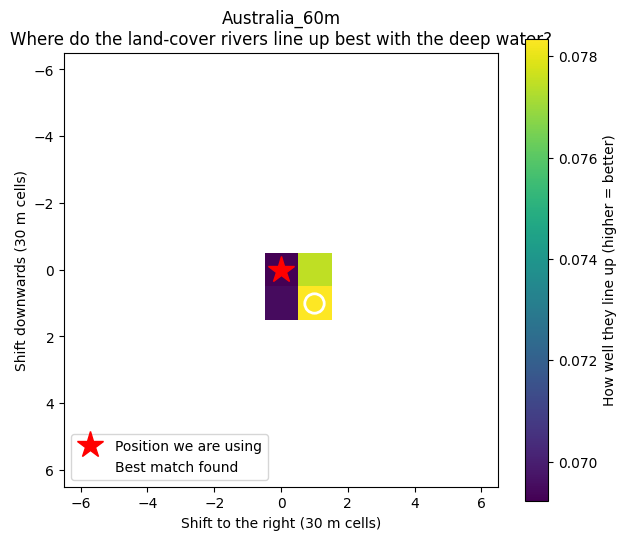

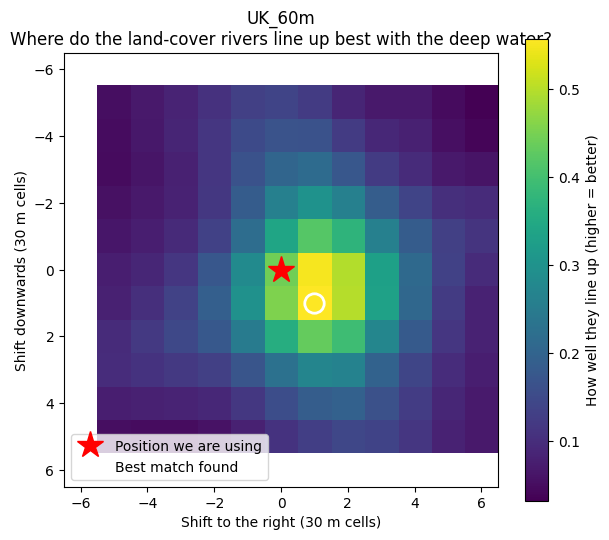

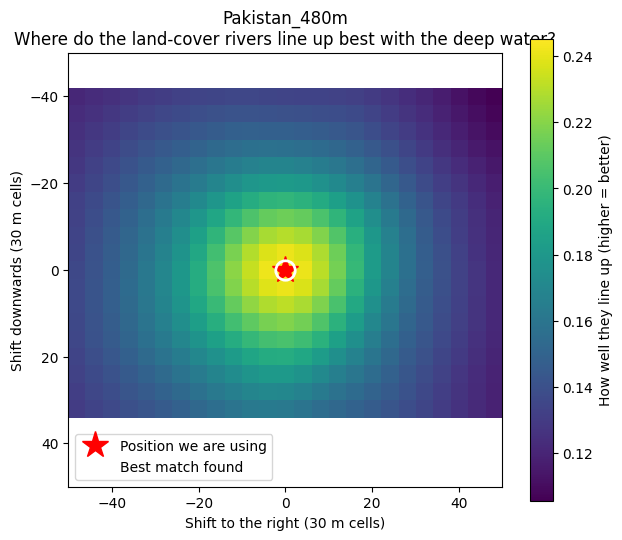

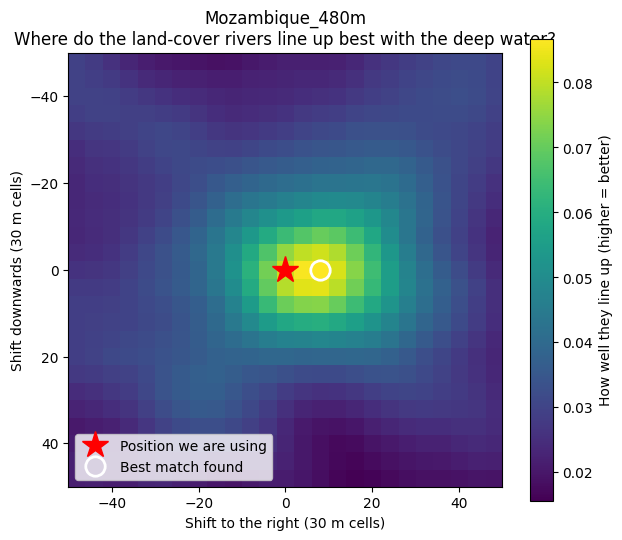

,Dataset,Best match: rows down (30 m cells),Best match: columns right (30 m cells),Distance from position in use (depth cells),Result
0,Australia_30m,0,0,0.0,OK
1,UK_30m,1,1,1.0,OK
2,Australia_60m,1,1,0.5,OK
3,UK_60m,1,1,0.5,OK
4,Pakistan_480m,0,0,0.0,OK
5,Mozambique_480m,0,8,0.5,OK


In [ ]:
check_rows = []

for dataset in DATASETS:
    scale = DATASETS[dataset]["scale"]
    scores, shifts = alignment_scores(dataset)

    # Shift with the best match
    best_i, best_j = np.unravel_index(np.nanargmax(scores), scores.shape)
    best_row_shift = shifts[best_i]
    best_column_shift = shifts[best_j]

    # Picture edges, so each square is centred on its shift value
    half_step = (shifts[1] - shifts[0]) / 2
    edges = [shifts[0] - half_step, shifts[-1] + half_step, shifts[-1] + half_step, shifts[0] - half_step]

    fig, ax = plt.subplots(figsize=(7, 6))

    picture = ax.imshow(scores, cmap="viridis", extent=edges)
    ax.plot(0, 0, marker="*", markersize=20, color="red", linestyle="none", label="Position we are using")
    ax.plot(best_column_shift, best_row_shift, marker="o", markersize=14, markerfacecolor="none",
            markeredgecolor="white", markeredgewidth=2, linestyle="none", label="Best match found")

    ax.set_xlabel("Shift to the right (30 m cells)")
    ax.set_ylabel("Shift downwards (30 m cells)")
    ax.set_title(dataset + "\nWhere do the land-cover rivers line up best with the deep water?")
    fig.colorbar(picture, ax=ax, label="How well they line up (higher = better)")
    ax.legend(loc="lower left")
    plt.show()

    # How far the best match is from the position in use, measured in depth cells
    distance = max(abs(best_row_shift), abs(best_column_shift)) / scale

    if distance <= 1:
        result = "OK"
    else:
        result = "CHECK"

    check_rows.append({
        "Dataset": dataset,
        "Best match: rows down (30 m cells)": best_row_shift,
        "Best match: columns right (30 m cells)": best_column_shift,
        "Distance from position in use (depth cells)": distance,
        "Result": result,
    })

display(pd.DataFrame(check_rows))

## Save ground height, land cover and rain
How rain is stored: `rain[t]` is the rain that falls **between** depth map t and depth map t+1.

    depth map 0         depth map 1         depth map 2
         |----- rain[0] -----|----- rain[1] -----|
       0 min              30 min              60 min

In [ ]:
for dataset, info in DATASETS.items():
    region = info["region"]
    rows, columns = DEPTH_SHAPES[dataset]
    dataset_dir = os.path.join(SAVE_DIR, dataset)

    # Ground height: the average height inside each depth cell
    dem_path = os.path.join(RAW_DIR, "Relevant data", "DEM", region + "_DEM.tif")
    terrain = read_on_depth_grid(dem_path, dataset, rows, columns, Resampling.average)
    np.save(os.path.join(dataset_dir, "terrain.npy"), terrain)

    # Land cover is a category, so each depth cell takes the most common category inside it
    land_cover_path = os.path.join(RAW_DIR, "Relevant data", "Land use and land cover", region + ".tif")
    land_cover = read_on_depth_grid(land_cover_path, dataset, rows, columns, Resampling.mode)
    land_cover = land_cover.astype("uint8")
    np.save(os.path.join(dataset_dir, "land_cover.npy"), land_cover)

    # Rivers and lakes that are there even without a flood
    permanent_water = land_cover == 1
    np.save(os.path.join(dataset_dir, "permanent_water.npy"), permanent_water)

    # Rain on the depth grid, one map per 30 minutes.
    # Stored as float16 to halve the file size: rain stays below about 20 mm per hour,
    # where float16 is accurate to about 0.02 mm per hour.
    number_of_maps = len(get_depth_files(dataset))
    rain_files = get_rain_files(region)
    rain = np.zeros((number_of_maps, rows, columns), dtype="float16")
    missing_rain = 0

    for step in range(number_of_maps):

        if step < len(rain_files):
            rain[step] = read_on_depth_grid(rain_files[step], dataset, rows, columns, Resampling.average)
        else:
            missing_rain += 1

        if step % 100 == 0:
            print(dataset, "- rain map", step, "of", number_of_maps)

    np.save(os.path.join(dataset_dir, "rain.npy"), rain)

    print(dataset, "- saved. Rain maps missing at the end (left as 0):", missing_rain)

Australia_30m - rain map 0 of 481
Australia_30m - rain map 100 of 481
Australia_30m - rain map 200 of 481
Australia_30m - rain map 300 of 481
Australia_30m - rain map 400 of 481
Australia_30m - saved. Rain maps missing at the end (left as 0): 0
UK_30m - rain map 0 of 145
UK_30m - rain map 100 of 145
UK_30m - saved. Rain maps missing at the end (left as 0): 0
Australia_60m - rain map 0 of 481
Australia_60m - rain map 100 of 481
Australia_60m - rain map 200 of 481
Australia_60m - rain map 300 of 481
Australia_60m - rain map 400 of 481
Australia_60m - saved. Rain maps missing at the end (left as 0): 0
UK_60m - rain map 0 of 145
UK_60m - rain map 100 of 145
UK_60m - saved. Rain maps missing at the end (left as 0): 0
Pakistan_480m - rain map 0 of 673
Pakistan_480m - rain map 100 of 673
Pakistan_480m - rain map 200 of 673
Pakistan_480m - rain map 300 of 673
Pakistan_480m - rain map 400 of 673
Pakistan_480m - rain map 500 of 673
Pakistan_480m - rain map 600 of 673
Pakistan_480m - saved. Rain 

## Save the map coordinates
Needed later to draw predictions on top of real satellite maps.

In [ ]:
coordinate_rows = []

for dataset, info in DATASETS.items():
    region = info["region"]
    rows, columns = DEPTH_SHAPES[dataset]
    scale = info["scale"]

    # A world file (.tfw) describes the 30 m grid in 6 numbers:
    # cell width, two rotation terms, cell height (negative), and the x and y of the top-left cell's centre
    tfw_path = os.path.join(RAW_DIR, "Relevant data", "DEM", region + "_DEM.tfw")

    with open(tfw_path) as file:
        numbers = [float(line) for line in file if line.strip()]

    cell_width, rotation_a, rotation_b, cell_height, centre_x, centre_y = numbers

    # Top-left corner of the 30 m grid (the world file gives the centre of the first cell, so move half a cell)
    grid_left = centre_x - cell_width / 2
    grid_top = centre_y - cell_height / 2

    # Top-left corner of the depth map inside the 30 m grid
    left = grid_left + info["col_offset"] * cell_width
    top = grid_top + info["row_offset"] * cell_height

    map_info = {
        "dataset": dataset,
        "region": region,
        "resolution_m": info["resolution_m"],
        "rows": rows,
        "columns": columns,
        "number_of_maps": len(get_depth_files(dataset)),
        "step_seconds": STEP_SECONDS,
        "epsg": EPSG_CODES[region],
        "transform": [cell_width * scale, 0.0, left, 0.0, cell_height * scale, top],
        "rain_meaning": "rain[t] is the rain in mm per hour falling between depth map t and depth map t+1",
    }

    with open(os.path.join(SAVE_DIR, dataset, "map_info.json"), "w") as file:
        json.dump(map_info, file, indent=2)

    coordinate_rows.append({
        "Dataset": dataset,
        "Cell size from world file (m)": abs(cell_width * scale),
        "Expected cell size (m)": info["resolution_m"],
        "Map rotated?": rotation_a != 0 or rotation_b != 0,
    })

display(pd.DataFrame(coordinate_rows))

,Dataset,Cell size from world file (m),Expected cell size (m),Map rotated?
0,Australia_30m,30.0,30,False
1,UK_30m,30.0,30,False
2,Australia_60m,60.0,60,False
3,UK_60m,60.0,60,False
4,Pakistan_480m,480.0,480,False
5,Mozambique_480m,480.0,480,False


## Final check: load the saved data back from Drive and look at it

In [ ]:
for dataset in DATASETS:
    dataset_dir = os.path.join(SAVE_DIR, dataset)

    # mmap_mode="r" reads from the file only when needed, so big arrays don't fill the memory
    depth = np.load(os.path.join(dataset_dir, "depth.npy"), mmap_mode="r")
    rain = np.load(os.path.join(dataset_dir, "rain.npy"), mmap_mode="r")
    terrain = np.load(os.path.join(dataset_dir, "terrain.npy"))
    land_cover = np.load(os.path.join(dataset_dir, "land_cover.npy"))
    permanent_water = np.load(os.path.join(dataset_dir, "permanent_water.npy"))

    # Find the moment when the largest area is under more than 30 cm of water
    deep_area = []

    for step in range(depth.shape[0]):
        deep_area.append(np.mean(depth[step] > 0.3))

    busiest = int(np.argmax(deep_area))
    hours = busiest * STEP_SECONDS / 3600

    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    fig.suptitle(dataset + " after " + str(round(hours)) + " hours: do all the layers line up?", fontsize=15)

    # Water depth, with the rivers and lakes from the land-cover map outlined in red
    water = np.array(depth[busiest])
    water[water < 0.01] = np.nan

    axes[0].set_facecolor("lightgrey")
    picture = axes[0].imshow(water, cmap=water_colours, vmin=0, vmax=np.nanpercentile(water, 98))
    axes[0].contour(permanent_water, levels=[0.5], colors="red", linewidths=0.6)
    axes[0].set_title("Water depth (grey = dry, red = rivers and lakes)")
    fig.colorbar(picture, ax=axes[0], label="metres")

    # Ground height
    picture = axes[1].imshow(terrain, cmap="terrain")
    axes[1].set_title("Ground height")
    fig.colorbar(picture, ax=axes[1], label="metres above sea level")

    # Land cover
    picture = axes[2].imshow(land_cover_positions(land_cover), cmap=land_cover_colours,
                             vmin=-0.5, vmax=len(LAND_COVER) - 0.5, interpolation="nearest")
    axes[2].set_title("What covers the ground")
    colour_bar = fig.colorbar(picture, ax=axes[2], ticks=range(len(LAND_COVER)))
    colour_bar.ax.set_yticklabels(land_cover_names)

    # Rain falling in the next 30 minutes
    picture = axes[3].imshow(np.array(rain[busiest], dtype="float32"), cmap="Greys")
    axes[3].set_title("Rain in the next 30 minutes")
    fig.colorbar(picture, ax=axes[3], label="mm per hour")

    for ax in axes:
        ax.axis("off")

    plt.show()

In [ ]:
# List every saved file and its size
file_rows = []

for dataset in DATASETS:
    dataset_dir = os.path.join(SAVE_DIR, dataset)

    for file_name in sorted(os.listdir(dataset_dir)):
        size_mb = os.path.getsize(os.path.join(dataset_dir, file_name)) / 1e6

        file_rows.append({
            "Dataset": dataset,
            "File": file_name,
            "Size (MB)": round(size_mb, 1),
        })

file_table = pd.DataFrame(file_rows)
display(file_table)

print("Total saved:", round(file_table["Size (MB)"].sum() / 1000, 2), "GB")

,Dataset,File,Size (MB)
0,Australia_30m,depth.npy,2215.2
1,Australia_30m,land_cover.npy,1.2
2,Australia_30m,map_info.json,0.0
3,Australia_30m,permanent_water.npy,1.2
4,Australia_30m,rain.npy,1107.6
5,Australia_30m,terrain.npy,4.6
6,UK_30m,depth.npy,27.1
7,UK_30m,land_cover.npy,0.0
8,UK_30m,map_info.json,0.0
9,UK_30m,permanent_water.npy,0.0


Total saved: 5.69 GB


## Alignment check, version 2
Two independent tests. Each one moves a 30 m map a little in every direction
and measures how well it matches where the flood water sits.
- Test 1: rivers and lakes on the land-cover map
- Test 2: valleys in the ground-height map

In [ ]:
from scipy.ndimage import uniform_filter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Download the ground-height and land-cover files again if this is a new Colab session (about 450 MB)
snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    local_dir=RAW_DIR,
    token=HF_TOKEN,
    allow_patterns=["Relevant data/DEM/*", "Relevant data/Land use and land cover/*"],
)

# Size and average depth of every dataset, read from the saved files on Drive
DEPTH_SHAPES = {}
depth_averages = {}

for dataset in DATASETS:
    depth = np.load(os.path.join(SAVE_DIR, dataset, "depth.npy"), mmap_mode="r")

    DEPTH_SHAPES[dataset] = (depth.shape[1], depth.shape[2])
    depth_averages[dataset] = np.mean(depth, axis=0)

    print(dataset, "- average depth map ready")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Australia_30m - average depth map ready
UK_30m - average depth map ready
Australia_60m - average depth map ready
UK_60m - average depth map ready
Pakistan_480m - average depth map ready
Mozambique_480m - average depth map ready


In [ ]:
def read_full_map(file_path):
    """Reads a whole 30 m map. No-data values are replaced by the map's average
    so they don't disturb the tests."""

    with rasterio.open(file_path) as source:
        data = source.read(1).astype("float32")

    no_data = data < -1e30
    data[no_data] = data[~no_data].mean()

    return data


def rivers_map(region):
    """1 where the land-cover map shows a river or lake, 0 everywhere else."""

    path = os.path.join(RAW_DIR, "Relevant data", "Land use and land cover", region + ".tif")
    land_cover = read_full_map(path)

    return (land_cover == 1).astype("float32")


def valleys_map(region, scale):
    """How much lower each 30 m cell is than the ground around it.
    River channels and valleys get high values."""

    path = os.path.join(RAW_DIR, "Relevant data", "DEM", region + "_DEM.tif")
    ground = read_full_map(path)

    # Average ground height in a square around each cell, about 10 depth cells wide
    surroundings = uniform_filter(ground, size=10 * scale + 1)

    return surroundings - ground


def shift_scores(dataset, reference):
    """Moves a 30 m reference map (rivers or valleys) a little in every direction and
    measures, for each move, how well it matches the flood's average depth."""

    info = DATASETS[dataset]
    scale = info["scale"]
    rows, columns = DEPTH_SHAPES[dataset]

    # Leave out a 3-cell border of the depth map, so every move stays inside the reference map
    border = 3
    depth_inner = depth_averages[dataset][border:rows - border, border:columns - border]
    inner_rows, inner_columns = depth_inner.shape

    # Moves of up to 3 depth cells in every direction
    largest_shift = border * scale
    shift_step = max(1, scale // 4)
    shifts = list(range(-largest_shift, largest_shift + 1, shift_step))

    scores = np.full((len(shifts), len(shifts)), np.nan)

    for i, row_shift in enumerate(shifts):
        for j, column_shift in enumerate(shifts):

            top = info["row_offset"] + border * scale + row_shift
            left = info["col_offset"] + border * scale + column_shift
            bottom = top + inner_rows * scale
            right = left + inner_columns * scale

            # Skip moves that would go past the edge of the reference map
            if top < 0 or left < 0 or bottom > reference.shape[0] or right > reference.shape[1]:
                continue

            # Shrink the moved piece onto the depth grid and compare it with the average depth
            piece = reference[top:bottom, left:right]
            piece_on_depth_grid = piece.reshape(inner_rows, scale, inner_columns, scale).mean(axis=(1, 3))

            scores[i, j] = np.corrcoef(piece_on_depth_grid.ravel(), depth_inner.ravel())[0, 1]

    return scores, shifts

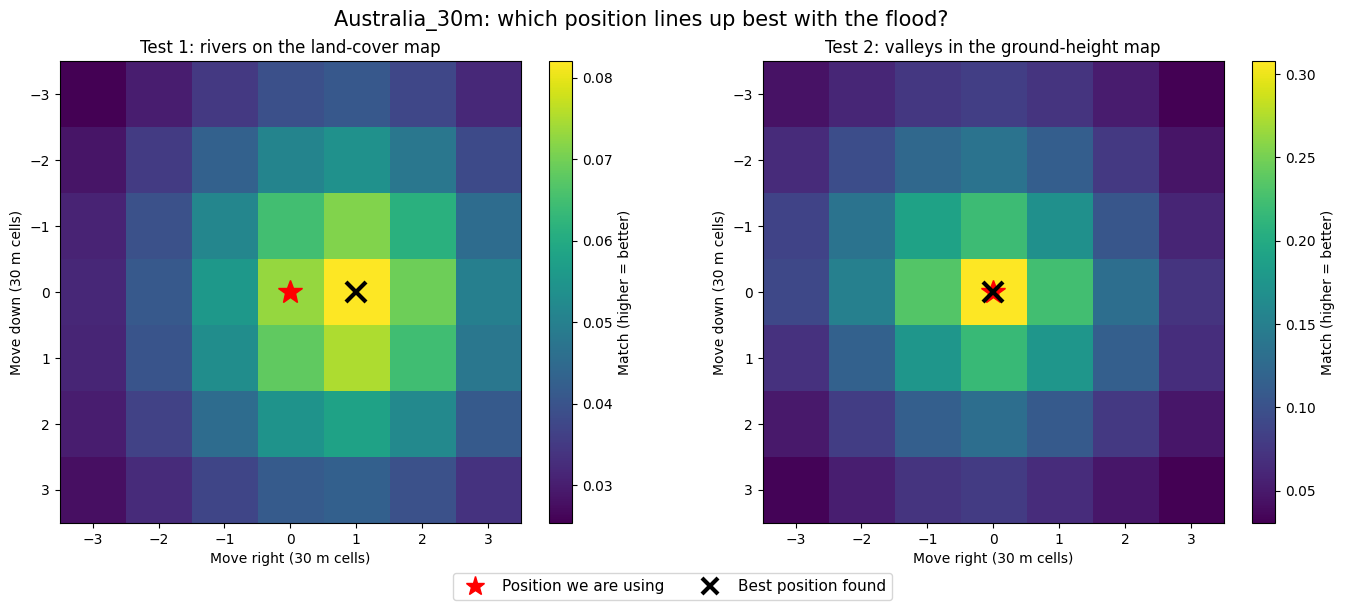

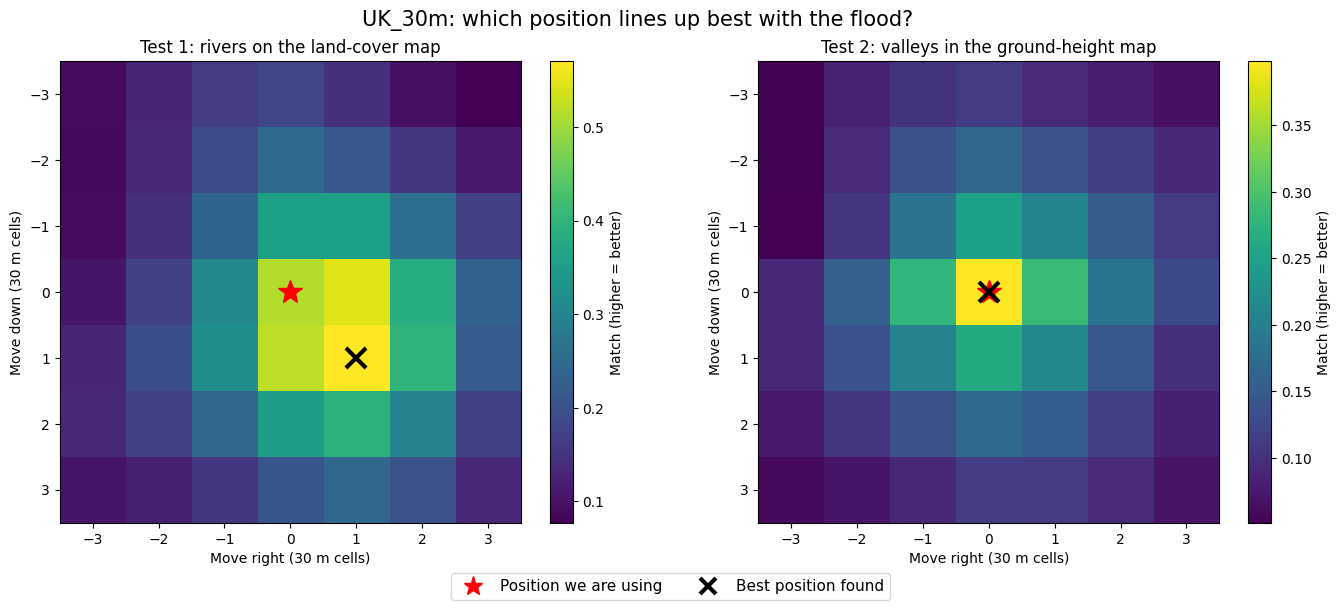

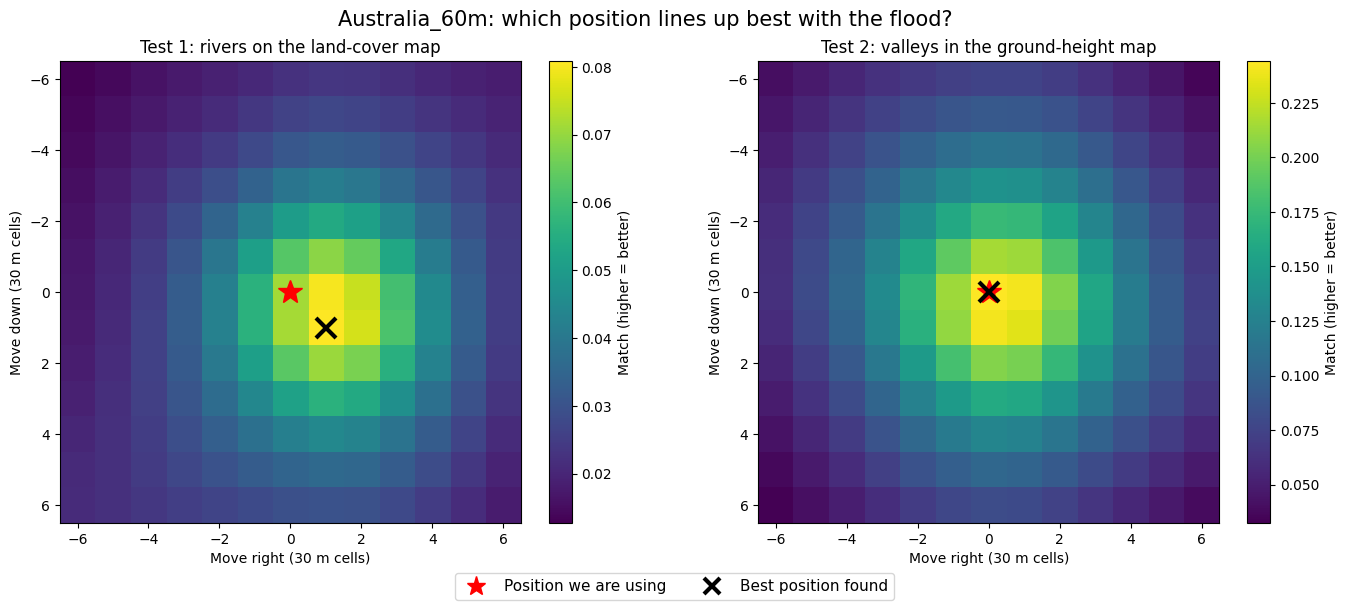

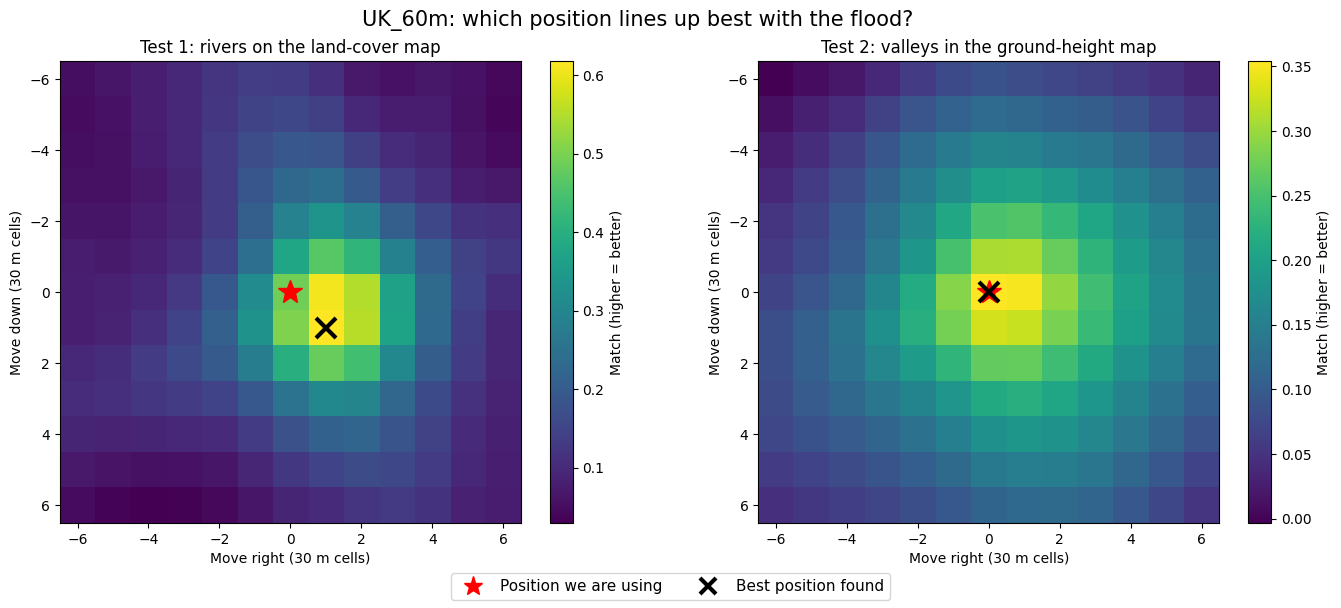

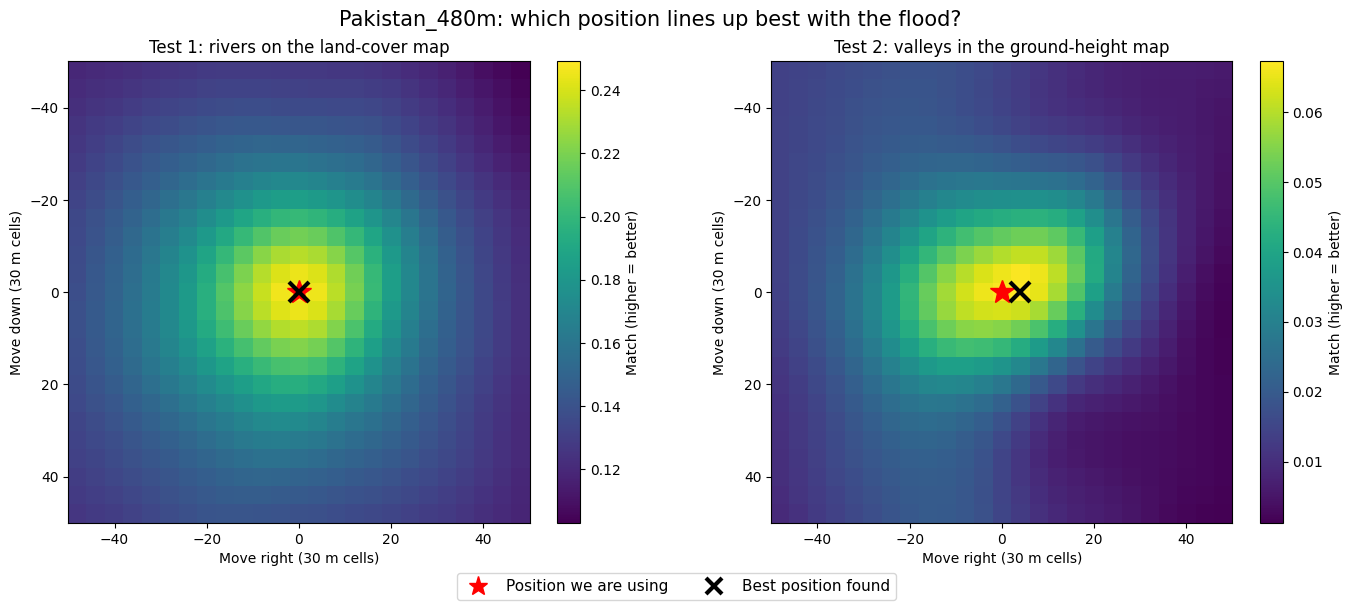

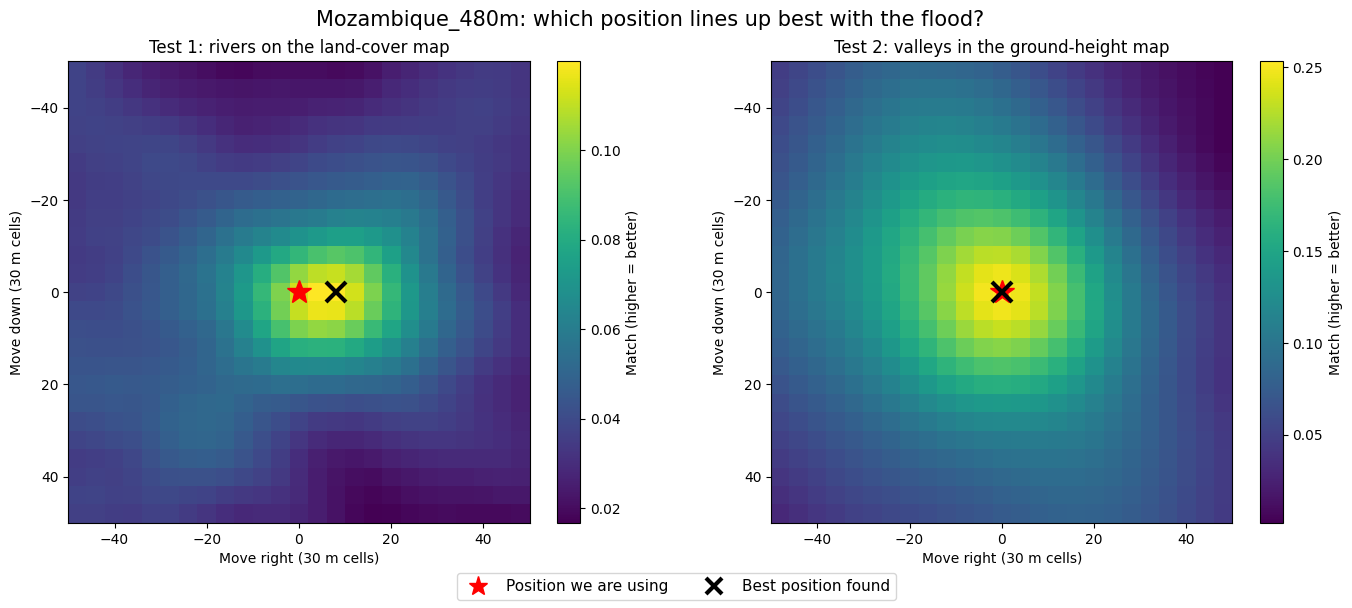

,Dataset,"Test 1 best move (down, right)","Test 2 best move (down, right)",Decision
0,Australia_30m,"(0, 1)","(0, 0)",Both tests say move it
1,UK_30m,"(1, 1)","(0, 0)",Both tests say move it
2,Australia_60m,"(1, 1)","(0, 0)",Keep the position
3,UK_60m,"(1, 1)","(0, 0)",Keep the position
4,Pakistan_480m,"(0, 0)","(0, 4)",Keep the position
5,Mozambique_480m,"(0, 8)","(0, 0)",Keep the position


In [ ]:
result_rows = []

for dataset, info in DATASETS.items():
    region = info["region"]
    scale = info["scale"]

    tests = {
        "Test 1: rivers on the land-cover map": rivers_map(region),
        "Test 2: valleys in the ground-height map": valleys_map(region, scale),
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
    fig.suptitle(dataset + ": which position lines up best with the flood?", fontsize=15)

    best_moves = []

    for ax, (test_name, reference) in zip(axes, tests.items()):
        scores, shifts = shift_scores(dataset, reference)

        # Move with the best match
        best_i, best_j = np.unravel_index(np.nanargmax(scores), scores.shape)
        best_moves.append((shifts[best_i], shifts[best_j]))

        # Picture edges, so each square is centred on its move
        half_step = (shifts[1] - shifts[0]) / 2
        edges = [shifts[0] - half_step, shifts[-1] + half_step, shifts[-1] + half_step, shifts[0] - half_step]

        picture = ax.imshow(scores, cmap="viridis", extent=edges)
        ax.plot(0, 0, marker="*", markersize=18, color="red", linestyle="none")
        ax.plot(shifts[best_j], shifts[best_i], marker="x", markersize=14, markeredgewidth=3,
                color="black", linestyle="none")

        ax.set_title(test_name)
        ax.set_xlabel("Move right (30 m cells)")
        ax.set_ylabel("Move down (30 m cells)")
        fig.colorbar(picture, ax=ax, label="Match (higher = better)")

    # One legend for both pictures, placed underneath them
    legend_items = [
        Line2D([], [], marker="*", markersize=14, color="red", linestyle="none", label="Position we are using"),
        Line2D([], [], marker="x", markersize=12, markeredgewidth=3, color="black", linestyle="none",
               label="Best position found"),
    ]
    fig.legend(handles=legend_items, loc="outside lower center", ncol=2, fontsize=11)
    plt.show()

    # A move smaller than half a depth cell makes no real difference
    rivers_move, valleys_move = best_moves
    rivers_close = max(abs(rivers_move[0]), abs(rivers_move[1])) <= scale / 2
    valleys_close = max(abs(valleys_move[0]), abs(valleys_move[1])) <= scale / 2

    # Do the two tests point to the same place?
    shift_step = max(1, scale // 4)
    tests_agree = (abs(rivers_move[0] - valleys_move[0]) <= shift_step and
                   abs(rivers_move[1] - valleys_move[1]) <= shift_step)

    if rivers_close and valleys_close:
        decision = "Keep the position"
    elif tests_agree:
        decision = "Both tests say move it"
    else:
        decision = "Tests disagree, look closer"

    result_rows.append({
        "Dataset": dataset,
        "Test 1 best move (down, right)": rivers_move,
        "Test 2 best move (down, right)": valleys_move,
        "Decision": decision,
    })

display(pd.DataFrame(result_rows))

## Final check, clearer version

In [ ]:
# Show missing values (dry land) as grey, even when the picture's axes are hidden
water_colours.set_bad("lightgrey")

for dataset in DATASETS:
    dataset_dir = os.path.join(SAVE_DIR, dataset)

    depth = np.load(os.path.join(dataset_dir, "depth.npy"), mmap_mode="r")
    rain = np.load(os.path.join(dataset_dir, "rain.npy"), mmap_mode="r")
    terrain = np.load(os.path.join(dataset_dir, "terrain.npy"))
    land_cover = np.load(os.path.join(dataset_dir, "land_cover.npy"))
    permanent_water = np.load(os.path.join(dataset_dir, "permanent_water.npy"))

    # Moment when the largest area is under more than 30 cm of water
    deep_area = []

    for step in range(depth.shape[0]):
        deep_area.append(np.mean(depth[step] > 0.3))

    busiest = int(np.argmax(deep_area))
    hours = busiest * STEP_SECONDS / 3600

    # Heaviest rain in the whole event, so the rain picture uses a fixed scale
    heaviest_rain = max(float(np.max(rain)), 1.0)

    fig, axes = plt.subplots(2, 2, figsize=(15, 12), layout="constrained")
    fig.suptitle(dataset + ", " + str(round(hours)) + " hours after the start", fontsize=17)

    # Top left: water depth, with rivers and lakes from the land-cover map outlined in red
    water = np.array(depth[busiest])
    water[water < 0.01] = np.nan

    picture = axes[0, 0].imshow(water, cmap=water_colours, vmin=0, vmax=np.nanpercentile(water, 98))
    axes[0, 0].contour(permanent_water, levels=[0.5], colors="red", linewidths=0.7)
    axes[0, 0].set_title("Water depth", fontsize=13)
    fig.colorbar(picture, ax=axes[0, 0], label="metres")

    depth_legend = [
        Patch(color="lightgrey", label="Dry (less than 1 cm of water)"),
        Line2D([], [], color="red", label="Rivers and lakes on the land-cover map"),
    ]
    axes[0, 0].legend(handles=depth_legend, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=9)

    # Top right: ground height
    picture = axes[0, 1].imshow(terrain, cmap="terrain")
    axes[0, 1].set_title("Ground height", fontsize=13)
    fig.colorbar(picture, ax=axes[0, 1], label="metres above sea level")

    # Bottom left: what covers the ground
    picture = axes[1, 0].imshow(land_cover_positions(land_cover), cmap=land_cover_colours,
                                vmin=-0.5, vmax=len(LAND_COVER) - 0.5, interpolation="nearest")
    axes[1, 0].set_title("What covers the ground", fontsize=13)
    colour_bar = fig.colorbar(picture, ax=axes[1, 0], ticks=range(len(LAND_COVER)))
    colour_bar.ax.set_yticklabels(land_cover_names)

    # Bottom right: rain falling in the next 30 minutes
    rain_now = np.array(rain[busiest], dtype="float32")

    picture = axes[1, 1].imshow(rain_now, cmap="Purples", vmin=0, vmax=heaviest_rain)
    axes[1, 1].set_title("Rain in the next 30 minutes", fontsize=13)
    fig.colorbar(picture, ax=axes[1, 1], label="mm per hour")

    if rain_now.max() == 0:
        axes[1, 1].text(0.5, 0.5, "No rain in this half hour", transform=axes[1, 1].transAxes,
                        ha="center", va="center", fontsize=14, backgroundcolor="white")

    for ax in axes.flat:
        ax.axis("off")

    plt.show()